# Notebook 2 (v2) — CMU-MOSEI fusion: saved models, multi-seed robustness, statistics

**What this version adds to v1 (training and models are unchanged):**
1. Every trained model is **saved** (checkpoint + validation/test probabilities + training log). If Colab disconnects,
   re-running the notebook **resumes** from the saved checkpoints instead of retraining.
2. All outputs go to a **new folder** (`emofar_results/mosei_v2_cpu/`). The v1 files are only read, never written.
3. A **repeatability check**: the new per-seed results are compared number-by-number with the v1 CSV.
4. **Robustness on all 3 training seeds × 5 masking seeds**, including a new "audio and video missing together" condition.
5. **Statistics**: mean ± SD, paired per-seed differences, paired bootstrap confidence intervals over test clips,
   and Holm correction for multiple comparisons.
6. The **gate diagnostic** on the full test set, for every seed.

**What is deliberately NOT changed** (so results stay comparable with v1): the four models, their hyperparameters,
the data preparation, the training loop and the model-selection rule. Known limitations of the code are listed in
Section 3 and will be studied as separate, controlled experiments.

**Runtime:** Colab → Runtime → Change runtime type → **CPU** + **High-RAM**. Run all cells top to bottom.

## 0. Setup and environment record

In [1]:
import os, sys, time, json, random, pickle, platform, warnings
warnings.filterwarnings("ignore", category=UserWarning)
IN_COLAB = "google.colab" in sys.modules
TEST_MODE = os.environ.get("EMOFAR_TEST") == "1"
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import sklearn
DEVICE = "cpu"                      # this version is meant for CPU: it is deterministic in this environment
torch.backends.cudnn.deterministic = True

def cpu_name():
    try:
        with open("/proc/cpuinfo") as f:
            for line in f:
                if line.startswith("model name"):
                    return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or "unknown"

ENV = {"python": platform.python_version(), "torch": torch.__version__, "numpy": np.__version__,
       "pandas": pd.__version__, "sklearn": sklearn.__version__, "cpu": cpu_name(),
       "torch_threads": torch.get_num_threads(), "os": platform.platform(),
       "started_utc": time.strftime("%Y-%m-%d %H:%M:%S", time.gmtime())}
print(json.dumps(ENV, indent=2))

Mounted at /content/drive
{
  "python": "3.13.18",
  "torch": "2.14.1+cpu",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "sklearn": "1.6.1",
  "cpu": "Intel(R) Xeon(R) CPU @ 2.20GHz",
  "torch_threads": 4,
  "os": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "started_utc": "2026-11-24 06:35:51"
}


## 1. Settings
Model and training settings are **identical to v1**. Only the output folder and evaluation settings are new.

In [2]:
DATA_PATH = "/content/drive/MyDrive/datasets/CMU-MOSEI/aligned_50.pkl"
BASE_OUT = "/content/drive/MyDrive/emofar_results"
PREV_RESULTS = f"{BASE_OUT}/mosei_results_all_seeds.csv"      # v1 results (read only)
PREV_ROBUST = f"{BASE_OUT}/mosei_robustness.csv"              # v1 robustness, seed 42 (read only)
RUN_DIR = f"{BASE_OUT}/mosei_v2_cpu"                          # everything new goes here
RESUME = True        # True: reuse checkpoints already saved in RUN_DIR (same code -> same models)

# --- identical to v1 ---
D_MODEL = 128
EPOCHS = 30
PATIENCE = 6
BATCH_SIZE = 64
LR = 5e-4
MOD_DROPOUT = 0.3
SEEDS = [42, 43, 44]
# --- new: evaluation only ---
MASK_SEEDS = [7, 8, 9, 10, 11]      # 5 random masking patterns per condition (seed 7 = the v1 pattern)
N_BOOT = 10000                      # bootstrap resamples of the test set
MISSING_RATES = (0.3, 0.5, 0.7)

if TEST_MODE:                       # only used to test this notebook outside Colab
    DATA_PATH, BASE_OUT = os.environ["EMOFAR_MOSI"], os.environ["EMOFAR_OUT"]
    PREV_RESULTS = os.environ.get("EMOFAR_PREV", f"{BASE_OUT}/none.csv")
    PREV_ROBUST = os.environ.get("EMOFAR_PREV_ROB", f"{BASE_OUT}/none.csv")
    RUN_DIR = f"{BASE_OUT}/mosei_v2_cpu"
    EPOCHS = int(os.environ.get("EMOFAR_EPOCHS", 3)); MASK_SEEDS = [7, 8]; N_BOOT = 500

CKPT_DIR = f"{RUN_DIR}/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)
assert os.path.abspath(RUN_DIR) != os.path.abspath(BASE_OUT), "RUN_DIR must be a separate folder"
LABELS = ["negative", "neutral", "positive"]
MODS = ["text", "audio", "vision"]

CONFIG = {k: v for k, v in dict(DATA_PATH=DATA_PATH, D_MODEL=D_MODEL, EPOCHS=EPOCHS, PATIENCE=PATIENCE,
          BATCH_SIZE=BATCH_SIZE, LR=LR, MOD_DROPOUT=MOD_DROPOUT, SEEDS=SEEDS, MASK_SEEDS=MASK_SEEDS,
          N_BOOT=N_BOOT, MISSING_RATES=MISSING_RATES).items()}
with open(f"{RUN_DIR}/run_info.json", "w") as f:
    json.dump({"environment": ENV, "config": CONFIG}, f, indent=2)
print("Outputs will be written to:", RUN_DIR)

Outputs will be written to: /content/drive/MyDrive/emofar_results/mosei_v2_cpu


## 2. Load the features (identical to v1)

In [3]:
t0 = time.time()
with open(DATA_PATH, "rb") as f:
    raw = pickle.load(f)
print(f"Loaded in {time.time() - t0:.0f}s")

def prep(split):
    d = raw[split]
    mask = d["text_bert"][:, 1, :].astype(bool)                        # (N, 50) real-word steps
    feats = {"text": d["text"].astype(np.float32),
             "audio": np.nan_to_num(d["audio"].astype(np.float32), nan=0.0, posinf=0.0, neginf=0.0),
             "vision": np.nan_to_num(d["vision"].astype(np.float32), nan=0.0, posinf=0.0, neginf=0.0)}
    score = d["regression_labels"].astype(np.float32)
    y = np.where(score < 0, 0, np.where(score == 0, 1, 2))
    return {"feats": feats, "mask": mask, "y": y, "score": score, "raw_text": d["raw_text"], "id": d["id"]}

data = {s: prep(s) for s in ["train", "valid", "test"]}
del raw

for m in ["audio", "vision"]:                                           # standardise with train statistics
    tr = data["train"]["feats"][m][data["train"]["mask"]]
    mu, sd = tr.mean(0), tr.std(0) + 1e-6
    for s in data:
        x = (data[s]["feats"][m] - mu) / sd
        data[s]["feats"][m] = np.clip(x, -10, 10) * data[s]["mask"][..., None]

DIMS = {m: data["train"]["feats"][m].shape[-1] for m in MODS}
print("Feature sizes:", DIMS)
for s in data:
    counts = np.bincount(data[s]["y"], minlength=3)
    print(f"{s:5s}: {len(data[s]['y']):6,} clips | " + " / ".join(f"{LABELS[i]} {counts[i]:,}" for i in range(3)))
np.save(f"{RUN_DIR}/test_labels.npy", data["test"]["y"]); np.save(f"{RUN_DIR}/valid_labels.npy", data["valid"]["y"])
np.save(f"{RUN_DIR}/test_scores.npy", data["test"]["score"])
pd.Series(data["test"]["id"]).to_csv(f"{RUN_DIR}/test_ids.csv", index=False, header=["id"])

Loaded in 46s
Feature sizes: {'text': 768, 'audio': 74, 'vision': 35}
train: 16,326 clips | negative 4,738 / neutral 3,540 / positive 8,048
valid:  1,871 clips | negative 506 / neutral 433 / positive 932
test :  4,659 clips | negative 1,350 / neutral 1,025 / positive 2,284


## 3. The four models (identical to v1)

| Model | What it is |
|---|---|
| **M1 Text-only** | average of text features → MLP |
| **M2 RMSR adaptation (Eq. 10–14)** | pooled vectors, `q = σ(u·z)`, `γ = softmax(q)`, single-vector attention. **No Eq. 15 alignment loss; pre-extracted features instead of the paper's encoders.** (The code keeps v1's label "M2 EMO-FAR RMSR (as written)" so files stay comparable.) |
| **M3 Fixed fusion** | token-level cross-attention + masked gate (missing modality → weight 0) + larger head |
| **M4 = M3 + modality dropout** | each modality hidden with probability 0.3 during training (at least one kept) |

**Known limitations, intentionally not changed in this run** (each needs its own controlled experiment):
- M2 and M3 differ in several components at once (projection/normalisation, attention, gate, masking, residual, head size).
- In M3/M4, a hidden modality's input is zeroed, but attention biases make its pooled summary a learned constant
  that still enters the gate scores of the other modalities (its own weight is exactly 0).
- The step mask comes from the text tokens even when text is hidden (it reveals utterance length).
- In training, when all three modalities are dropped (2.7 % of samples), one is restored at random,
  so the effective dropout rate is slightly below 0.3.

In [4]:
def masked_mean(x, mask):
    m = mask.unsqueeze(-1).float()
    return (x * m).sum(1) / m.sum(1).clamp(min=1)

class TextOnly(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(DIMS["text"], D_MODEL), nn.ReLU(), nn.Dropout(0.2), nn.Linear(D_MODEL, 3))
    def forward(self, x, mask, avail, return_gate=False):
        out = self.net(masked_mean(x["text"], mask))
        return (out, None) if return_gate else out

class PaperRMSR(nn.Module):
    """Equation-level adaptation of EMO-FAR's RMSR (Eq. 10-14)."""
    def __init__(self):
        super().__init__()
        self.proj = nn.ModuleDict({m: nn.Linear(DIMS[m], D_MODEL) for m in MODS})          # Eq. 10
        self.u = nn.ParameterDict({m: nn.Parameter(torch.randn(D_MODEL) * 0.05) for m in MODS})  # Eq. 11
        self.Wq, self.Wk, self.Wv = (nn.Linear(D_MODEL, D_MODEL) for _ in range(3))
        self.cls = nn.Sequential(nn.Dropout(0.2), nn.Linear(D_MODEL, 3))
    def forward(self, x, mask, avail, return_gate=False):
        z = {m: self.proj[m](masked_mean(x[m], mask)) for m in MODS}
        q = torch.stack([torch.sigmoid((z[m] * self.u[m]).sum(-1)) for m in MODS], -1)   # Eq. 11
        gamma = q.softmax(-1)                                                             # Eq. 12
        att = {}
        for m in ["audio", "vision"]:                                                     # Eq. 13
            score = (self.Wq(z["text"]) * self.Wk(z[m])).sum(-1, keepdim=True) / D_MODEL ** 0.5
            att[m] = score.softmax(-1) * self.Wv(z[m])
        h = gamma[:, :1] * z["text"] + gamma[:, 1:2] * att["audio"] + gamma[:, 2:] * att["vision"]   # Eq. 14
        out = self.cls(h)
        return (out, gamma) if return_gate else out

class FixedFusion(nn.Module):
    """Token-level cross-attention + masked gating."""
    def __init__(self):
        super().__init__()
        self.proj = nn.ModuleDict({m: nn.Sequential(nn.Linear(DIMS[m], D_MODEL), nn.LayerNorm(D_MODEL)) for m in MODS})
        self.xattn = nn.ModuleDict({m: nn.MultiheadAttention(D_MODEL, 4, batch_first=True, dropout=0.1)
                                    for m in ["audio", "vision"]})
        self.gate = nn.Linear(3 * D_MODEL, 3)
        self.cls = nn.Sequential(nn.Dropout(0.2), nn.Linear(D_MODEL, D_MODEL), nn.ReLU(), nn.Linear(D_MODEL, 3))
    def forward(self, x, mask, avail, return_gate=False):
        p = {m: self.proj[m](x[m]) * avail[:, i, None, None] for i, m in enumerate(MODS)}
        h = {"text": masked_mean(p["text"], mask)}
        for m in ["audio", "vision"]:
            attended, _ = self.xattn[m](p["text"], p[m], p[m], key_padding_mask=~mask)
            h[m] = masked_mean(attended + p[m], mask)
        logits = self.gate(torch.cat([h[m] for m in MODS], -1))
        logits = logits.masked_fill(avail == 0, float("-inf"))
        w = logits.softmax(-1)
        fused = sum(w[:, i:i + 1] * h[m] for i, m in enumerate(MODS))
        out = self.cls(fused)
        return (out, w) if return_gate else out

MODELS = {"M1 Text-only": (TextOnly, 0.0),
          "M2 EMO-FAR RMSR (as written)": (PaperRMSR, 0.0),
          "M3 Fixed fusion": (FixedFusion, 0.0),
          "M4 Fixed fusion + modality dropout": (FixedFusion, MOD_DROPOUT)}
SHORT = {name: name.split()[0] for name in MODELS}                     # "M1" ... "M4"

## 4. Training and evaluation functions (identical to v1)
The only change: `train()` now also **returns** the best validation macro-F1 and the stopping epoch
(v1 only printed them). No computation is changed.

In [5]:
from sklearn.metrics import f1_score, accuracy_score

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def sample_avail(n, rates, rng):
    """rates = (p_text, p_audio, p_vision): chance each modality is hidden. At least one stays."""
    avail = (rng.rand(n, 3) >= np.array(rates)).astype(np.float32)
    none_left = avail.sum(1) == 0
    avail[none_left, rng.randint(0, 3, none_left.sum())] = 1
    return avail

def to_batch(d, idx, avail):
    x = {m: torch.from_numpy(d["feats"][m][idx]).to(DEVICE) for m in MODS}
    for i, m in enumerate(MODS):
        x[m] = x[m] * torch.from_numpy(avail[:, i]).to(DEVICE)[:, None, None]
    return x, torch.from_numpy(d["mask"][idx]).to(DEVICE), torch.from_numpy(avail).to(DEVICE)

@torch.no_grad()
def predict(model, d, rates=(0, 0, 0), seed=0):
    model.eval(); rng = np.random.RandomState(seed); out = []
    for i in range(0, len(d["y"]), 256):
        idx = np.arange(i, min(i + 256, len(d["y"])))
        x, mask, avail = to_batch(d, idx, sample_avail(len(idx), rates, rng))
        out.append(model(x, mask, avail).softmax(-1).cpu().numpy())
    return np.concatenate(out)

def ece_score(probs, y, n_bins=15):
    conf, pred = probs.max(1), probs.argmax(1); ece = 0.0
    for lo, hi in zip(np.linspace(0, 1, n_bins + 1)[:-1], np.linspace(0, 1, n_bins + 1)[1:]):
        sel = (conf > lo) & (conf <= hi)
        if sel.any():
            ece += sel.mean() * abs((pred[sel] == y[sel]).mean() - conf[sel].mean())
    return float(ece)

def evaluate(probs, d):
    y, pred = d["y"], probs.argmax(1)
    nz = d["score"] != 0
    acc2 = ((probs[nz, 2] > probs[nz, 0]) == (d["score"][nz] > 0)).mean()
    return {"accuracy": accuracy_score(y, pred), "macro_f1": f1_score(y, pred, average="macro"),
            "acc2": float(acc2), "ece": ece_score(probs, y)}

def train(name, seed):
    cls, drop = MODELS[name]
    set_seed(seed)
    model = cls().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    counts = np.bincount(data["train"]["y"], minlength=3)
    class_w = torch.tensor(counts.sum() / (3 * counts), dtype=torch.float, device=DEVICE)
    rng = np.random.RandomState(seed); tr = data["train"]
    best, best_state, bad = -1, None, 0
    for ep in range(EPOCHS):
        model.train()
        order = rng.permutation(len(tr["y"]))
        for i in range(0, len(order), BATCH_SIZE):
            idx = order[i:i + BATCH_SIZE]
            x, mask, avail = to_batch(tr, idx, sample_avail(len(idx), (drop, drop, drop), rng))
            loss = F.cross_entropy(model(x, mask, avail), torch.from_numpy(tr["y"][idx]).to(DEVICE), weight=class_w)
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        val = evaluate(predict(model, data["valid"]), data["valid"])["macro_f1"]
        if val > best:
            best, bad = val, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state)
    print(f"  {name:38s} seed {seed}: best valid macro-F1 = {best:.4f}  (stopped after epoch {ep + 1})")
    return model, float(best), ep + 1

def save_atomic(save_fn, path):
    """Write to a temporary file first, then rename: a disconnect never leaves a half-written file."""
    tmp = path + ".tmp"
    save_fn(tmp)
    os.replace(tmp, path)

## 5. Train (or resume) all 12 runs and save everything
For each model × seed this saves: `<M>_seed<s>.pt` (weights), `<M>_seed<s>_test_probs.npy`,
`<M>_seed<s>_valid_probs.npy` and `<M>_seed<s>_log.json` (best validation F1, stopping epoch, time).

In [6]:
# Settings that determine a trained model. A saved checkpoint is reused only if these match exactly.
TRAIN_CONFIG = dict(D_MODEL=D_MODEL, EPOCHS=EPOCHS, PATIENCE=PATIENCE, BATCH_SIZE=BATCH_SIZE, LR=LR,
                    MOD_DROPOUT=MOD_DROPOUT, DATA_PATH=DATA_PATH, n_train=int(len(data["train"]["y"])))
results, trained = [], {}
for name in MODELS:
    for seed in SEEDS:
        tag = f"{SHORT[name]}_seed{seed}"
        ckpt, logf = f"{CKPT_DIR}/{tag}.pt", f"{CKPT_DIR}/{tag}_log.json"
        if RESUME and os.path.exists(ckpt) and os.path.exists(logf):
            model = MODELS[name][0]().to(DEVICE)
            model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
            log = json.load(open(logf))
            assert log.get("train_config") == TRAIN_CONFIG, (
                f"{ckpt} was trained with different settings {log.get('train_config')}; "
                "use a new RUN_DIR or set RESUME = False")
            print(f"  {name:38s} seed {seed}: loaded saved checkpoint")
        else:
            t1 = time.time()
            model, best, stop_ep = train(name, seed)
            log = {"model": name, "seed": seed, "best_valid_macro_f1": best, "stopped_epoch": stop_ep,
                   "train_seconds": round(time.time() - t1, 1), "train_config": TRAIN_CONFIG}
            save_atomic(lambda p: torch.save(model.state_dict(), p), ckpt)
            save_atomic(lambda p: json.dump(log, open(p, "w"), indent=2), logf)
        test_probs, valid_probs = predict(model, data["test"]), predict(model, data["valid"])
        np.save(f"{CKPT_DIR}/{tag}_test_probs.npy", test_probs)
        np.save(f"{CKPT_DIR}/{tag}_valid_probs.npy", valid_probs)
        r = evaluate(test_probs, data["test"])
        r.update(model=name, seed=seed, best_valid_macro_f1=log["best_valid_macro_f1"], stopped_epoch=log["stopped_epoch"])
        results.append(r)
        trained[(name, seed)] = model
res = pd.DataFrame(results)
res.to_csv(f"{RUN_DIR}/main_results_per_seed.csv", index=False)
print(f"\nSaved {len(trained)} models to {CKPT_DIR}")

  M1 Text-only                           seed 42: best valid macro-F1 = 0.6244  (stopped after epoch 12)
  M1 Text-only                           seed 43: best valid macro-F1 = 0.6254  (stopped after epoch 14)
  M1 Text-only                           seed 44: best valid macro-F1 = 0.6277  (stopped after epoch 14)
  M2 EMO-FAR RMSR (as written)           seed 42: best valid macro-F1 = 0.6181  (stopped after epoch 9)
  M2 EMO-FAR RMSR (as written)           seed 43: best valid macro-F1 = 0.6095  (stopped after epoch 7)
  M2 EMO-FAR RMSR (as written)           seed 44: best valid macro-F1 = 0.6209  (stopped after epoch 10)
  M3 Fixed fusion                        seed 42: best valid macro-F1 = 0.6269  (stopped after epoch 12)
  M3 Fixed fusion                        seed 43: best valid macro-F1 = 0.6309  (stopped after epoch 10)
  M3 Fixed fusion                        seed 44: best valid macro-F1 = 0.6256  (stopped after epoch 7)
  M4 Fixed fusion + modality dropout     seed 42: best val

## 6. Main results: per seed and mean ± SD
SD = sample standard deviation over the 3 training seeds (ddof = 1). With 3 seeds, SD is itself very uncertain.

In [7]:
METRICS = ["accuracy", "macro_f1", "acc2", "ece"]
per_seed = res.pivot(index="seed", columns="model", values="macro_f1")[list(MODELS)].rename(columns=SHORT)
print("Test macro-F1 per seed:"); print(per_seed.round(4))
summary = res.groupby("model", sort=False)[METRICS].agg(["mean", "std"])
summary.to_csv(f"{RUN_DIR}/main_results_summary.csv")
fmt = pd.DataFrame({m: [f"{summary.loc[n, (m, 'mean')]:.4f} ± {summary.loc[n, (m, 'std')]:.4f}" for n in MODELS]
                    for m in METRICS}, index=list(MODELS))
fmt

Test macro-F1 per seed:
model      M1      M2      M3      M4
seed                                 
42     0.6289  0.6272  0.6276  0.6373
43     0.6361  0.6169  0.6397  0.6287
44     0.6308  0.6240  0.6188  0.6374


,accuracy,macro_f1,acc2,ece
M1 Text-only,0.6525 ± 0.0088,0.6319 ± 0.0037,0.8385 ± 0.0046,0.0177 ± 0.0048
M2 EMO-FAR RMSR (as written),0.6511 ± 0.0069,0.6227 ± 0.0053,0.8296 ± 0.0027,0.0210 ± 0.0018
M3 Fixed fusion,0.6642 ± 0.0057,0.6287 ± 0.0105,0.8349 ± 0.0039,0.0356 ± 0.0184
M4 Fixed fusion + modality dropout,0.6619 ± 0.0082,0.6345 ± 0.0050,0.8369 ± 0.0048,0.0206 ± 0.0057


## 7. Repeatability check against v1
Compares every v1 number with this run. "Identical" here means **the same code on the same kind of environment
gives the same numbers** (repeatability). It does not show that other hardware or library versions would.

In [8]:
if os.path.exists(PREV_RESULTS):
    prev = pd.read_csv(PREV_RESULTS)
    merged = prev.merge(res, on=["model", "seed"], suffixes=("_v1", "_v2"))
    diffs = {m: float((merged[f"{m}_v1"] - merged[f"{m}_v2"]).abs().max()) for m in METRICS}
    print(f"Runs compared: {len(merged)} of {len(res)}")
    print("Largest absolute difference per metric:", {k: f"{v:.2e}" for k, v in diffs.items()})
    print("IDENTICAL to v1" if max(diffs.values()) < 1e-9 else "DIFFERENT from v1 — investigate before using these results")
    json.dump({"compared_runs": len(merged), "max_abs_diff": diffs, "environment": ENV},
              open(f"{RUN_DIR}/repeatability_check.json", "w"), indent=2)
else:
    print("No v1 results file found at", PREV_RESULTS, "— repeatability check skipped.")

Runs compared: 12 of 12
Largest absolute difference per metric: {'accuracy': '1.18e-02', 'macro_f1': '5.74e-03', 'acc2': '9.63e-03', 'ece': '2.93e-02'}
DIFFERENT from v1 — investigate before using these results


## 8. Statistical comparison of models
Two different sources of uncertainty are reported separately:
- **Across training seeds:** the per-seed paired difference (same seed, two models), its mean ± SD, and how many seeds are positive.
  A paired t-test with 3 seeds has only 2 degrees of freedom, so it is shown for completeness, not as proof.
- **Across test clips:** a **paired bootstrap** — the test set is resampled with replacement 10,000 times, and both models
  are scored on the same resampled clips. This gives a 95 % confidence interval for the macro-F1 difference
  (averaged over the 3 seeds) and a two-sided p-value. **Holm correction** adjusts the p-values for making 4 comparisons.

In [9]:
from scipy import stats

y_test = data["test"]["y"]
probs_test = {(n, s): np.load(f"{CKPT_DIR}/{SHORT[n]}_seed{s}_test_probs.npy") for n in MODELS for s in SEEDS}
preds_test = {k: v.argmax(1) for k, v in probs_test.items()}

def macro_f1_fast(y, p):
    cm = np.bincount(y * 3 + p, minlength=9).reshape(3, 3)
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    denom = 2 * tp + fp + fn
    return np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0.0).mean()

k0 = next(iter(preds_test))
assert abs(macro_f1_fast(y_test, preds_test[k0]) - f1_score(y_test, preds_test[k0], average="macro")) < 1e-12

PAIRS = [("M4 Fixed fusion + modality dropout", "M2 EMO-FAR RMSR (as written)"),
         ("M4 Fixed fusion + modality dropout", "M3 Fixed fusion"),
         ("M3 Fixed fusion", "M2 EMO-FAR RMSR (as written)"),
         ("M4 Fixed fusion + modality dropout", "M1 Text-only")]
rng_b = np.random.RandomState(2026)
boot_idx = rng_b.randint(0, len(y_test), size=(N_BOOT, len(y_test)))

rows = []
for a, b in PAIRS:
    seed_diffs = [macro_f1_fast(y_test, preds_test[(a, s)]) - macro_f1_fast(y_test, preds_test[(b, s)]) for s in SEEDS]
    t_p = stats.ttest_rel([macro_f1_fast(y_test, preds_test[(a, s)]) for s in SEEDS],
                          [macro_f1_fast(y_test, preds_test[(b, s)]) for s in SEEDS]).pvalue if len(SEEDS) > 1 else np.nan
    boot = np.empty(N_BOOT)
    for i, idx in enumerate(boot_idx):
        yb = y_test[idx]
        boot[i] = np.mean([macro_f1_fast(yb, preds_test[(a, s)][idx]) - macro_f1_fast(yb, preds_test[(b, s)][idx]) for s in SEEDS])
    # two-sided bootstrap p-value; the +1 terms stop it from ever being reported as exactly 0
    p_boot = min(1.0, 2 * (min((boot <= 0).sum(), (boot >= 0).sum()) + 1) / (N_BOOT + 1))
    rows.append({"comparison": f"{SHORT[a]} − {SHORT[b]}",
                 "per_seed_diff_pp": ", ".join(f"{100 * d:+.2f}" for d in seed_diffs),
                 "mean_diff_pp": 100 * np.mean(seed_diffs), "sd_diff_pp": 100 * np.std(seed_diffs, ddof=1) if len(SEEDS) > 1 else np.nan,
                 "seeds_positive": f"{sum(d > 0 for d in seed_diffs)}/{len(SEEDS)}",
                 "paired_t_p (df=2)": t_p,
                 "boot_95CI_pp": f"[{100 * np.percentile(boot, 2.5):+.2f}, {100 * np.percentile(boot, 97.5):+.2f}]",
                 "boot_p": p_boot})
stat_df = pd.DataFrame(rows)
order = np.argsort(stat_df["boot_p"].values); m = len(order); holm = np.empty(m); running = 0.0
for rank, i in enumerate(order):                                      # Holm step-down adjustment
    running = max(running, min(1.0, (m - rank) * stat_df["boot_p"].values[i])); holm[i] = running
stat_df["boot_p_holm"] = holm
stat_df.to_csv(f"{RUN_DIR}/statistics_main.csv", index=False)
stat_df.round(4)

,comparison,per_seed_diff_pp,mean_diff_pp,sd_diff_pp,seeds_positive,paired_t_p (df=2),boot_95CI_pp,boot_p,boot_p_holm
0,M4 − M2,"+1.01, +1.18, +1.34",1.1771,0.1659,3/3,0.0066,"[+0.41, +1.93]",0.0020,0.0080
1,M4 − M3,"+0.97, -1.09, +1.86",0.5801,1.5164,2/3,0.5757,"[-0.05, +1.22]",0.0724,0.2172
2,M3 − M2,"+0.03, +2.28, -0.52",0.5970,1.4821,2/3,0.5576,"[-0.07, +1.27]",0.0830,0.2172
3,M4 − M1,"+0.84, -0.73, +0.66",0.2581,0.8636,2/3,0.6563,"[-0.37, +0.89]",0.4170,0.4170


## 9. Robustness: all 3 training seeds × 5 masking seeds
Conditions:
- **audio+video hidden independently** at 30/50/70 % (as in v1: each hidden separately, so both are missing in r² of clips);
- **audio AND video hidden together** at 30/50/70 % (new: only text remains for those clips);
- **text hidden** at 30/50/70 % (audio and video kept).
The "all present" condition has no randomness, so it is evaluated once per model.
Every prediction is saved (`robustness_probs/`), so any later analysis needs no re-running.

In [10]:
@torch.no_grad()
def predict_avail(model, d, avail_all):
    model.eval(); out = []
    for i in range(0, len(d["y"]), 256):
        idx = np.arange(i, min(i + 256, len(d["y"])))
        x, mask, avail = to_batch(d, idx, avail_all[idx])
        out.append(model(x, mask, avail).softmax(-1).cpu().numpy())
    return np.concatenate(out)

def avail_independent(n, rates, seed):
    """Same random stream as v1's predict(): batches of 256 drawn in order."""
    rng = np.random.RandomState(seed)
    return np.concatenate([sample_avail(min(256, n - i), rates, rng) for i in range(0, n, 256)])

def avail_joint_av(n, r, seed):
    rng = np.random.RandomState(seed)
    avail = np.ones((n, 3), dtype=np.float32)
    both = rng.rand(n) < r
    avail[both, 1] = 0; avail[both, 2] = 0
    return avail

N_TEST = len(data["test"]["y"])
CONDITIONS = [("all present", lambda s: np.ones((N_TEST, 3), dtype=np.float32), False)]
CONDITIONS += [(f"A+V hidden independently {int(r*100)}%", (lambda r: lambda s: avail_independent(N_TEST, (0, r, r), s))(r), True) for r in MISSING_RATES]
CONDITIONS += [(f"A+V hidden together {int(r*100)}%", (lambda r: lambda s: avail_joint_av(N_TEST, r, s))(r), True) for r in MISSING_RATES]
CONDITIONS += [(f"text hidden {int(r*100)}%", (lambda r: lambda s: avail_independent(N_TEST, (r, 0, 0), s))(r), True) for r in MISSING_RATES]

ROB_DIR = f"{RUN_DIR}/robustness_probs"; os.makedirs(ROB_DIR, exist_ok=True)
rob_rows = []
t0 = time.time()
for cond, make_avail, random_cond in CONDITIONS:
    for ms in (MASK_SEEDS if random_cond else [None]):
        avail_all = make_avail(ms)
        for (name, seed), model in trained.items():
            probs = predict_avail(model, data["test"], avail_all)
            m_ = evaluate(probs, data["test"])
            rob_rows.append({"condition": cond, "model": name, "train_seed": seed, "mask_seed": ms, **m_})
            np.save(f"{ROB_DIR}/{SHORT[name]}_seed{seed}_{cond.replace(' ', '_').replace('%', 'pct').replace('+', 'plus')}_mask{ms}.npy",
                    probs.astype(np.float32))
    print(f"  {cond:32s} done ({time.time() - t0:.0f}s)")
rob = pd.DataFrame(rob_rows)
rob.to_csv(f"{RUN_DIR}/robustness_all_runs.csv", index=False)

# v1 equivalence: seed 42, mask seed 7, independent conditions must reproduce v1's table
if os.path.exists(PREV_ROBUST):
    prev_rob = pd.read_csv(PREV_ROBUST).set_index("scenario")
    name_map = {"all present": "all present"}
    name_map.update({f"audio+video hidden {int(r*100)}%": f"A+V hidden independently {int(r*100)}%" for r in MISSING_RATES})
    name_map.update({f"text hidden {int(r*100)}%": f"text hidden {int(r*100)}%" for r in MISSING_RATES})
    worst = 0.0
    for old, new in name_map.items():
        for name in MODELS:
            sel = rob[(rob.condition == new) & (rob.model == name) & (rob.train_seed == SEEDS[0]) &
                      ((rob.mask_seed == 7) | rob.mask_seed.isna())]
            worst = max(worst, abs(float(sel.macro_f1.iloc[0]) - float(prev_rob.loc[old, name])))
    print("Largest difference from the v1 robustness table:", f"{worst:.2e}", "(IDENTICAL)" if worst < 1e-9 else "(DIFFERENT — investigate)")

  all present                      done (15s)
  A+V hidden independently 30%     done (90s)
  A+V hidden independently 50%     done (168s)
  A+V hidden independently 70%     done (245s)
  A+V hidden together 30%          done (317s)
  A+V hidden together 50%          done (392s)
  A+V hidden together 70%          done (465s)
  text hidden 30%                  done (537s)
  text hidden 50%                  done (603s)
  text hidden 70%                  done (666s)
Largest difference from the v1 robustness table: 4.59e-03 (DIFFERENT — investigate)


### 9b. Robustness summary
For each condition and model: first average the masking seeds within each training seed, then report
**mean ± SD over the 3 training seeds**. `mask_sd` = average spread caused by the masking pattern alone.

In [11]:
per_train = rob.groupby(["condition", "model", "train_seed"], sort=False).macro_f1.mean().reset_index()
mask_sd = rob.groupby(["condition", "model", "train_seed"], sort=False).macro_f1.std().groupby(["condition", "model"], sort=False).mean()
rob_sum = per_train.groupby(["condition", "model"], sort=False).macro_f1.agg(["mean", "std"])
rob_sum["mask_sd"] = mask_sd
rob_sum.to_csv(f"{RUN_DIR}/robustness_summary.csv")
rob_table = pd.DataFrame({SHORT[n]: [f"{rob_sum.loc[(c, n), 'mean']:.4f} ± {rob_sum.loc[(c, n), 'std']:.4f}" for c, _, _ in CONDITIONS]
                          for n in MODELS}, index=[c for c, _, _ in CONDITIONS])
rob_table

,M1,M2,M3,M4
all present,0.6319 ± 0.0037,0.6227 ± 0.0053,0.6287 ± 0.0105,0.6345 ± 0.0050
A+V hidden independently 30%,0.6319 ± 0.0037,0.6215 ± 0.0035,0.6263 ± 0.0098,0.6333 ± 0.0047
A+V hidden independently 50%,0.6319 ± 0.0037,0.6207 ± 0.0035,0.6252 ± 0.0088,0.6317 ± 0.0051
A+V hidden independently 70%,0.6319 ± 0.0037,0.6198 ± 0.0021,0.6233 ± 0.0087,0.6300 ± 0.0048
A+V hidden together 30%,0.6319 ± 0.0037,0.6217 ± 0.0038,0.6273 ± 0.0096,0.6321 ± 0.0050
A+V hidden together 50%,0.6319 ± 0.0037,0.6198 ± 0.0030,0.6256 ± 0.0083,0.6303 ± 0.0035
A+V hidden together 70%,0.6319 ± 0.0037,0.6183 ± 0.0026,0.6240 ± 0.0079,0.6288 ± 0.0036
text hidden 30%,0.5335 ± 0.0196,0.5468 ± 0.0079,0.5580 ± 0.0049,0.5687 ± 0.0060
text hidden 50%,0.4573 ± 0.0304,0.4975 ± 0.0157,0.5117 ± 0.0035,0.5281 ± 0.0069
text hidden 70%,0.3600 ± 0.0384,0.4447 ± 0.0244,0.4622 ± 0.0071,0.4821 ± 0.0060


### 9c. Paired robustness differences (same training seed, masking seeds averaged)

In [12]:
rob_pairs = []
for cond, _, _ in CONDITIONS:
    for a, b in PAIRS[:3]:
        va = per_train[(per_train.condition == cond) & (per_train.model == a)].set_index("train_seed").macro_f1
        vb = per_train[(per_train.condition == cond) & (per_train.model == b)].set_index("train_seed").macro_f1
        d = (va - vb).loc[SEEDS] * 100
        rob_pairs.append({"condition": cond, "comparison": f"{SHORT[a]} − {SHORT[b]}",
                          "per_seed_pp": ", ".join(f"{x:+.2f}" for x in d), "mean_pp": d.mean(),
                          "sd_pp": d.std(ddof=1) if len(d) > 1 else np.nan, "seeds_positive": f"{int((d > 0).sum())}/{len(d)}"})
rob_pairs_df = pd.DataFrame(rob_pairs)
rob_pairs_df.to_csv(f"{RUN_DIR}/robustness_paired_differences.csv", index=False)
rob_pairs_df.round(3)

,condition,comparison,per_seed_pp,mean_pp,sd_pp,seeds_positive
0,all present,M4 − M2,"+1.01, +1.18, +1.34",1.177,0.166,3/3
1,all present,M4 − M3,"+0.97, -1.09, +1.86",0.580,1.516,2/3
2,all present,M3 − M2,"+0.03, +2.28, -0.52",0.597,1.482,2/3
3,A+V hidden independently 30%,M4 − M2,"+1.06, +1.02, +1.46",1.180,0.245,3/3
4,A+V hidden independently 30%,M4 − M3,"+0.99, -0.87, +1.98",0.697,1.446,2/3
5,A+V hidden independently 30%,M3 − M2,"+0.08, +1.89, -0.52",0.483,1.251,2/3
6,A+V hidden independently 50%,M4 − M2,"+0.83, +0.93, +1.56",1.108,0.395,3/3
7,A+V hidden independently 50%,M4 − M3,"+0.86, -0.83, +1.92",0.651,1.388,2/3
8,A+V hidden independently 50%,M3 − M2,"-0.02, +1.76, -0.36",0.457,1.138,1/3
9,A+V hidden independently 70%,M4 − M2,"+0.83, +0.70, +1.52",1.016,0.441,3/3


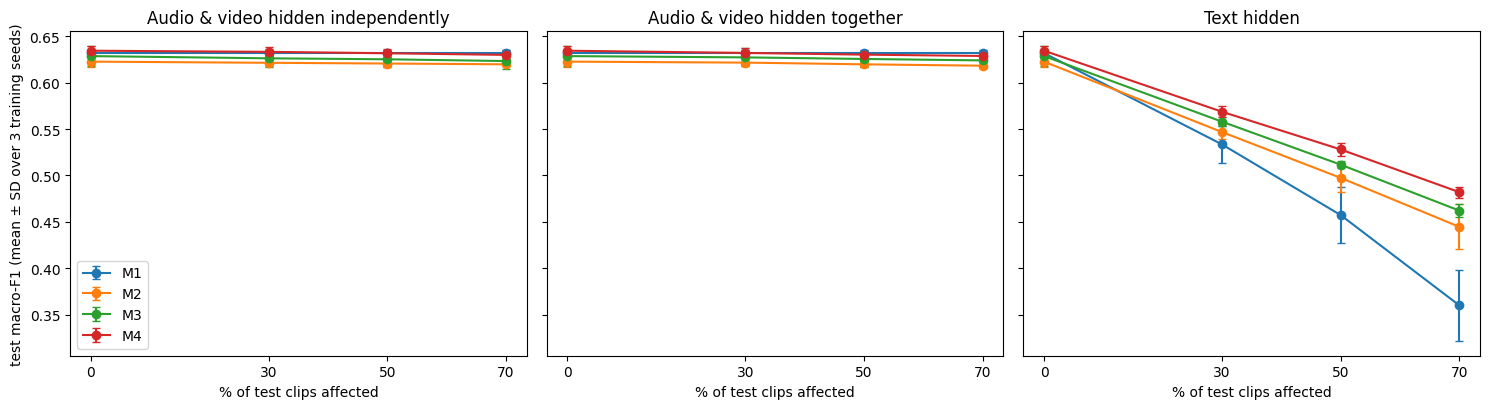

In [13]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
groups = [("A+V hidden independently", "Audio & video hidden independently"),
          ("A+V hidden together", "Audio & video hidden together"),
          ("text hidden", "Text hidden")]
for ax, (prefix, title) in zip(axes, groups):
    xs = [0] + [int(r * 100) for r in MISSING_RATES]
    for n in MODELS:
        means = [rob_sum.loc[("all present", n), "mean"]] + [rob_sum.loc[(f"{prefix} {x}%", n), "mean"] for x in xs[1:]]
        sds = [rob_sum.loc[("all present", n), "std"]] + [rob_sum.loc[(f"{prefix} {x}%", n), "std"] for x in xs[1:]]
        ax.errorbar(xs, means, yerr=sds, marker="o", capsize=3, label=SHORT[n])
    ax.set_title(title); ax.set_xlabel("% of test clips affected"); ax.set_xticks(xs)
axes[0].set_ylabel("test macro-F1 (mean ± SD over 3 training seeds)"); axes[0].legend()
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/robustness.png", dpi=150); plt.show()

## 10. Gate diagnostic on the full test set, all seeds
For each gated model, one modality is hidden for **every** test clip, and we record the weight the gate still gives it.
M2's Eq. 12 bound with 3 modalities is [1/(1+2e), e/(e+2)] = [0.155, 0.576]; a masked gate should give exactly 0.

In [14]:
gate_rows = []
with torch.no_grad():
    for (name, seed), model in trained.items():
        if name.startswith("M1"):
            continue
        for hide_i, hide_m in enumerate(MODS):
            ws = []
            for i in range(0, N_TEST, 256):
                idx = np.arange(i, min(i + 256, N_TEST))
                avail = np.ones((len(idx), 3), dtype=np.float32); avail[:, hide_i] = 0
                x, mask, av = to_batch(data["test"], idx, avail)
                _, w = model.eval()(x, mask, av, return_gate=True)
                ws.append(w[:, hide_i].cpu().numpy())
            ws = np.concatenate(ws)
            gate_rows.append({"model": SHORT[name], "seed": seed, "hidden": hide_m,
                              "min_weight": float(ws.min()), "mean_weight": float(ws.mean()), "max_weight": float(ws.max())})
gate_df = pd.DataFrame(gate_rows)
gate_df.to_csv(f"{RUN_DIR}/gate_diagnostic.csv", index=False)
print(f"Eq. 12 theoretical bounds: [{1/(1+2*np.e):.3f}, {np.e/(np.e+2):.3f}]")
gate_df.round(3)

Eq. 12 theoretical bounds: [0.155, 0.576]


,model,seed,hidden,min_weight,mean_weight,max_weight
0,M2,42,text,0.274,0.355,0.426
1,M2,42,audio,0.239,0.278,0.352
2,M2,42,vision,0.241,0.278,0.331
3,M2,43,text,0.311,0.354,0.398
4,M2,43,audio,0.248,0.270,0.292
5,M2,43,vision,0.240,0.263,0.295
6,M2,44,text,0.277,0.359,0.423
7,M2,44,audio,0.234,0.281,0.370
8,M2,44,vision,0.222,0.275,0.357
9,M3,42,text,0.000,0.000,0.000


## 11. Files written by this run
Everything is in `RUN_DIR`; the v1 files in `emofar_results/` were only read.

In [15]:
total = 0
for root, _, files in os.walk(RUN_DIR):
    for fn in sorted(files):
        total += os.path.getsize(os.path.join(root, fn))
n_files = sum(len(f) for _, _, f in os.walk(RUN_DIR))
print(f"{n_files} files, {total / 1e6:.1f} MB in {RUN_DIR}")
for fn in sorted(os.listdir(RUN_DIR)):
    print("  ", fn)

614 files, 41.8 MB in /content/drive/MyDrive/emofar_results/mosei_v2_cpu
   checkpoints
   gate_diagnostic.csv
   main_results_per_seed.csv
   main_results_summary.csv
   repeatability_check.json
   robustness.png
   robustness_all_runs.csv
   robustness_paired_differences.csv
   robustness_probs
   robustness_summary.csv
   run_info.json
   statistics_main.csv
   test_ids.csv
   test_labels.npy
   test_scores.npy
   valid_labels.npy
